# Proyek Analisis Data: Air Quality Dataset
- **Nama:** Rekyan Setyoputri Prameswari
- **Email:** rekyanstyptri@gmail.com
- **ID Dicoding:** rekyanstyptrii14

## Menentukan Pertanyaan Bisnis

- **Pola Tren Kualitas Udara**: Bagaimana pola konsentrasi PM2.5 di Beijing selama periode 2013 hingga 2017? Kapan polusi paling parah terjadi (tahunan, musiman, dan harian)?
- **Pengaruh Cuaca:** Seberapa besar hubungan antara faktor meteorologis, seperti kecepatan angin, suhu, dan kelembapan, dengan konsentrasi PM2.5 di Beijing? Faktor manakah yang memiliki hubungan paling kuat dengan perubahan konsentrasi PM2.5?
- **Analisis Lanjutan:** Bagaimana stasiun-stasiun pemantauan kualitas udara di Beijing dapat dikelompokkan berdasarkan kesamaan karakteristik konsentrasi PM2.5 dan kondisi meteorologis, serta apa karakteristik utama yang membedakan setiap kelompok?

## Import Semua Packages/Library yang Digunakan

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#**INFORMASI DATASET**



## Data Wrangling

### Gathering Data

In [33]:
# Memuat data tabel aotizhongxin
aotizhongxin_df = pd.read_csv("/content/PRSA_Data_Aotizhongxin_20130301-20170228.csv")
aotizhongxin_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [34]:
# Memuat data tabel changping
changping_df = pd.read_csv("/content/PRSA_Data_Changping_20130301-20170228.csv")
changping_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,3.0,6.0,13.0,7.0,300.0,85.0,-2.3,1020.8,-19.7,0.0,E,0.5,Changping
1,2,2013,3,1,1,3.0,3.0,6.0,6.0,300.0,85.0,-2.5,1021.3,-19.0,0.0,ENE,0.7,Changping
2,3,2013,3,1,2,3.0,3.0,22.0,13.0,400.0,74.0,-3.0,1021.3,-19.9,0.0,ENE,0.2,Changping
3,4,2013,3,1,3,3.0,6.0,12.0,8.0,300.0,81.0,-3.6,1021.8,-19.1,0.0,NNE,1.0,Changping
4,5,2013,3,1,4,3.0,3.0,14.0,8.0,300.0,81.0,-3.5,1022.3,-19.4,0.0,N,2.1,Changping


In [35]:
# Memuat data tabel dingling
dingling_df = pd.read_csv("/content/PRSA_Data_Dingling_20130301-20170228.csv")
dingling_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,3.0,NaN,200.0,82.0,-2.3,1020.8,-19.7,0.0,E,0.5,Dingling
1,2,2013,3,1,1,7.0,7.0,3.0,NaN,200.0,80.0,-2.5,1021.3,-19.0,0.0,ENE,0.7,Dingling
2,3,2013,3,1,2,5.0,5.0,3.0,2.0,200.0,79.0,-3.0,1021.3,-19.9,0.0,ENE,0.2,Dingling
3,4,2013,3,1,3,6.0,6.0,3.0,NaN,200.0,79.0,-3.6,1021.8,-19.1,0.0,NNE,1.0,Dingling
4,5,2013,3,1,4,5.0,5.0,3.0,NaN,200.0,81.0,-3.5,1022.3,-19.4,0.0,N,2.1,Dingling


In [36]:
# Memuat data tabel dongsi
dongsi_df = pd.read_csv("/content/PRSA_Data_Dongsi_20130301-20170228.csv")
dongsi_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,9.0,9.0,3.0,17.0,300.0,89.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Dongsi
1,2,2013,3,1,1,4.0,4.0,3.0,16.0,300.0,88.0,-0.7,1025.1,-22.1,0.0,NW,3.9,Dongsi
2,3,2013,3,1,2,7.0,7.0,NaN,17.0,300.0,60.0,-1.2,1025.3,-24.6,0.0,NNW,5.3,Dongsi
3,4,2013,3,1,3,3.0,3.0,5.0,18.0,NaN,NaN,-1.4,1026.2,-25.5,0.0,N,4.9,Dongsi
4,5,2013,3,1,4,3.0,3.0,7.0,NaN,200.0,84.0,-1.9,1027.1,-24.5,0.0,NNW,3.2,Dongsi


In [37]:
# Memuat data tabel guanyuan
# Catatan: Jika error berlanjut, harap pastikan file terunggah dengan lengkap tanpa korupsi.
guanyuan_df = pd.read_csv("/content/PRSA_Data_Guanyuan_20130301-20170228.csv", quoting=3)
guanyuan_df.head()

,"""No""","""year""","""month""","""day""","""hour""","""PM2.5""","""PM10""","""SO2""","""NO2""","""CO""","""O3""","""TEMP""","""PRES""","""DEWP""","""RAIN""","""wd""","""WSPM""","""station"""
0,1,2013,3,1,0,4.0,4.0,14.0,20.0,300.0,69.0,-0.7,1023.0,-18.8,0.0,"""NNW""",4.4,"""Guanyuan"""
1,2,2013,3,1,1,4.0,4.0,13.0,17.0,300.0,72.0,-1.1,1023.2,-18.2,0.0,"""N""",4.7,"""Guanyuan"""
2,3,2013,3,1,2,3.0,3.0,10.0,19.0,300.0,69.0,-1.1,1023.5,-18.2,0.0,"""NNW""",5.6,"""Guanyuan"""
3,4,2013,3,1,3,3.0,6.0,7.0,24.0,400.0,62.0,-1.4,1024.5,-19.4,0.0,"""NW""",3.1,"""Guanyuan"""
4,5,2013,3,1,4,3.0,6.0,5.0,14.0,400.0,71.0,-2.0,1025.2,-19.5,0.0,"""N""",2.0,"""Guanyuan"""


In [38]:
# Memuat data tabel gucheng
gucheng_df = pd.read_csv("/content/PRSA_Data_Gucheng_20130301-20170228.csv")
gucheng_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,6.0,18.0,5.0,NaN,800.0,88.0,0.1,1021.1,-18.6,0.0,NW,4.4,Gucheng
1,2,2013,3,1,1,6.0,15.0,5.0,NaN,800.0,88.0,-0.3,1021.5,-19.0,0.0,NW,4.0,Gucheng
2,3,2013,3,1,2,5.0,18.0,NaN,NaN,700.0,52.0,-0.7,1021.5,-19.8,0.0,WNW,4.6,Gucheng
3,4,2013,3,1,3,6.0,20.0,6.0,NaN,NaN,NaN,-1.0,1022.7,-21.2,0.0,W,2.8,Gucheng
4,5,2013,3,1,4,5.0,17.0,5.0,NaN,600.0,73.0,-1.3,1023.0,-21.4,0.0,WNW,3.6,Gucheng


In [39]:
# Memuat data tabel huairou
huairou_df = pd.read_csv("/content/PRSA_Data_Huairou_20130301-20170228.csv")
huairou_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,7.0,7.0,3.0,2.0,100.0,91.0,-2.3,1020.3,-20.7,0.0,WNW,3.1,Huairou
1,2,2013,3,1,1,4.0,4.0,3.0,NaN,100.0,92.0,-2.7,1020.8,-20.5,0.0,NNW,1.5,Huairou
2,3,2013,3,1,2,4.0,4.0,NaN,NaN,100.0,91.0,-3.2,1020.6,-21.4,0.0,NW,1.8,Huairou
3,4,2013,3,1,3,3.0,3.0,3.0,2.0,NaN,NaN,-3.3,1021.3,-23.7,0.0,NNW,2.4,Huairou
4,5,2013,3,1,4,3.0,3.0,7.0,NaN,300.0,86.0,-4.1,1022.1,-22.7,0.0,NNW,2.2,Huairou


In [40]:
# Memuat data tabel nongzhanguan
nongzhanguan_df = pd.read_csv("/content/PRSA_Data_Nongzhanguan_20130301-20170228.csv", quoting=3)
nongzhanguan_df.head()

,"""No""","""year""","""month""","""day""","""hour""","""PM2.5""","""PM10""","""SO2""","""NO2""","""CO""","""O3""","""TEMP""","""PRES""","""DEWP""","""RAIN""","""wd""","""WSPM""","""station"""
0,1,2013,3,1,0,5.0,14.0,4.0,12.0,200.0,85.0,-0.5,1024.5,-21.4,0.0,"""NNW""",5.7,"""Nongzhanguan"""
1,2,2013,3,1,1,8.0,12.0,6.0,14.0,200.0,84.0,-0.7,1025.1,-22.1,0.0,"""NW""",3.9,"""Nongzhanguan"""
2,3,2013,3,1,2,3.0,6.0,5.0,14.0,200.0,83.0,-1.2,1025.3,-24.6,0.0,"""NNW""",5.3,"""Nongzhanguan"""
3,4,2013,3,1,3,5.0,5.0,5.0,14.0,200.0,84.0,-1.4,1026.2,-25.5,0.0,"""N""",4.9,"""Nongzhanguan"""
4,5,2013,3,1,4,5.0,5.0,6.0,21.0,200.0,77.0,-1.9,1027.1,-24.5,0.0,"""NNW""",3.2,"""Nongzhanguan"""


In [41]:
# Memuat data tabel shunyi
shunyi_df = pd.read_csv("/content/PRSA_Data_Shunyi_20130301-20170228.csv")
shunyi_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,3.0,6.0,3.0,8.0,300.0,44.0,-0.9,1025.8,-20.5,0.0,NW,9.3,Shunyi
1,2,2013,3,1,1,12.0,12.0,3.0,7.0,300.0,47.0,-1.1,1026.1,-21.3,0.0,NW,9.4,Shunyi
2,3,2013,3,1,2,14.0,14.0,NaN,7.0,200.0,22.0,-1.7,1026.2,-23.0,0.0,NW,8.6,Shunyi
3,4,2013,3,1,3,12.0,12.0,3.0,5.0,NaN,NaN,-2.1,1027.3,-23.3,0.0,NW,6.6,Shunyi
4,5,2013,3,1,4,12.0,12.0,3.0,NaN,200.0,11.0,-2.4,1027.7,-22.9,0.0,NW,4.5,Shunyi


In [42]:
# Memuat data tabel tiantan
tiantan_df = pd.read_csv("/content/PRSA_Data_Tiantan_20130301-20170228.csv")
tiantan_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,6.0,6.0,4.0,8.0,300.0,81.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Tiantan
1,2,2013,3,1,1,6.0,29.0,5.0,9.0,300.0,80.0,-0.7,1025.1,-22.1,0.0,NW,3.9,Tiantan
2,3,2013,3,1,2,6.0,6.0,4.0,12.0,300.0,75.0,-1.2,1025.3,-24.6,0.0,NNW,5.3,Tiantan
3,4,2013,3,1,3,6.0,6.0,4.0,12.0,300.0,74.0,-1.4,1026.2,-25.5,0.0,N,4.9,Tiantan
4,5,2013,3,1,4,5.0,5.0,7.0,15.0,400.0,70.0,-1.9,1027.1,-24.5,0.0,NNW,3.2,Tiantan


In [43]:
# Memuat data tabel wanliu
wanliu_df = pd.read_csv("/content/PRSA_Data_Wanliu_20130301-20170228.csv")
wanliu_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,8.0,8.0,6.0,28.0,400.0,52.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Wanliu
1,2,2013,3,1,1,9.0,9.0,6.0,28.0,400.0,50.0,-1.1,1023.2,-18.2,0.0,N,4.7,Wanliu
2,3,2013,3,1,2,3.0,6.0,NaN,19.0,400.0,55.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Wanliu
3,4,2013,3,1,3,11.0,30.0,8.0,14.0,NaN,NaN,-1.4,1024.5,-19.4,0.0,NW,3.1,Wanliu
4,5,2013,3,1,4,3.0,13.0,9.0,NaN,300.0,54.0,-2.0,1025.2,-19.5,0.0,N,2.0,Wanliu


In [44]:
# Memuat data tabel wanshouxigong
wanshouxigong_df = pd.read_csv("/content/PRSA_Data_Wanshouxigong_20130301-20170228.csv")
wanshouxigong_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,9.0,9.0,6.0,17.0,200.0,62.0,0.3,1021.9,-19.0,0.0,WNW,2.0,Wanshouxigong
1,2,2013,3,1,1,11.0,11.0,7.0,14.0,200.0,66.0,-0.1,1022.4,-19.3,0.0,WNW,4.4,Wanshouxigong
2,3,2013,3,1,2,8.0,8.0,NaN,16.0,200.0,59.0,-0.6,1022.6,-19.7,0.0,WNW,4.7,Wanshouxigong
3,4,2013,3,1,3,8.0,8.0,3.0,16.0,NaN,NaN,-0.7,1023.5,-20.9,0.0,NW,2.6,Wanshouxigong
4,5,2013,3,1,4,8.0,8.0,3.0,NaN,300.0,36.0,-0.9,1024.1,-21.7,0.0,WNW,2.5,Wanshouxigong


**Insight:**
- Dataset terdiri dari 12 file berformat CSV yang terpisah, dengan setiap file merepresentasikan data pengamatan dari satu stasiun pemantauan kualitas udara di Beijing.
- Seluruh dataset memiliki struktur variabel yang serupa, mencakup tiga kategori utama, yaitu informasi waktu (year, month, day, hour), konsentrasi polutan (PM2.5, PM10, SO2, NO2, CO, O3), dan kondisi meteorologis (TEMP, PRES, DEWP, RAIN, wd, WSPM).
- Data mencakup periode 1 Maret 2013 hingga 28 Februari 2017, dengan frekuensi pengamatan setiap jam selama 4 tahun


### Assessing Data

In [45]:
# Menilai data aotizhongxin
aotizhongxin_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12971 entries, 0 to 12970
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       12971 non-null  int64  
 1   year     12971 non-null  int64  
 2   month    12971 non-null  int64  
 3   day      12971 non-null  int64  
 4   hour     12971 non-null  int64  
 5   PM2.5    12846 non-null  float64
 6   PM10     12857 non-null  float64
 7   SO2      12756 non-null  float64
 8   NO2      12775 non-null  float64
 9   CO       11979 non-null  float64
 10  O3       12270 non-null  float64
 11  TEMP     12970 non-null  float64
 12  PRES     12970 non-null  float64
 13  DEWP     12970 non-null  float64
 14  RAIN     12970 non-null  float64
 15  wd       12968 non-null  object 
 16  WSPM     12970 non-null  float64
 17  station  12970 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 1.8+ MB


In [46]:
print("Jumlah duplikasi:", aotizhongxin_df.duplicated().sum())

Jumlah duplikasi: 0


In [47]:
aotizhongxin_df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,12971.000000,12971.000000,12971.000000,12971.000000,12971.000000,12846.000000,12857.000000,12756.000000,12775.000000,11979.000000,12270.000000,12970.000000,12970.000000,12970.000000,12970.000000,12970.000000
mean,6486.000000,2013.433814,6.155269,15.578521,11.494488,86.383287,116.222136,24.445331,61.997422,1169.189248,53.952872,15.528651,1008.359106,5.993570,0.070031,1.535759
std,3744.549506,0.495619,3.034971,8.760757,6.922717,76.473786,90.783887,28.886996,33.372674,993.751953,57.107013,10.945559,9.796185,13.124163,1.001460,1.128647
min,1.000000,2013.000000,1.000000,1.000000,0.000000,3.000000,1.000000,0.285600,2.000000,100.000000,0.214200,-12.200000,985.900000,-28.100000,0.000000,0.000000
25%,3243.500000,2013.000000,4.000000,8.000000,5.000000,28.000000,46.000000,5.000000,37.000000,500.000000,4.000000,6.200000,1000.200000,-4.500000,0.000000,0.800000
50%,6486.000000,2013.000000,6.000000,16.000000,11.000000,66.000000,98.000000,13.000000,58.000000,900.000000,38.770200,17.600000,1007.500000,7.300000,0.000000,1.300000
75%,9728.500000,2014.000000,8.000000,23.000000,17.000000,121.000000,162.000000,32.000000,83.000000,1500.000000,81.000000,24.200000,1016.000000,18.000000,0.000000,2.000000
max,12971.000000,2014.000000,12.000000,31.000000,23.000000,665.000000,948.000000,197.000000,228.000000,8900.000000,358.999200,40.500000,1032.900000,28.500000,72.500000,9.100000


In [48]:
# Menilai data changping
changping_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34290 non-null  float64
 6   PM10     34482 non-null  float64
 7   SO2      34436 non-null  float64
 8   NO2      34397 non-null  float64
 9   CO       33543 non-null  float64
 10  O3       34460 non-null  float64
 11  TEMP     35011 non-null  float64
 12  PRES     35014 non-null  float64
 13  DEWP     35011 non-null  float64
 14  RAIN     35013 non-null  float64
 15  wd       34924 non-null  object 
 16  WSPM     35021 non-null  float64
 17  station  35064 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 4.8+ MB


In [49]:
print("Jumlah duplikasi:", changping_df.duplicated().sum())

Jumlah duplikasi: 0


In [50]:
changping_df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,35064.000000,35064.000000,35064.000000,35064.000000,35064.000000,34290.000000,34482.000000,34436.000000,34397.000000,33543.000000,34460.000000,35011.000000,35014.000000,35011.000000,35013.000000,35021.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,71.099743,94.657871,14.958906,44.182086,1152.301345,57.940003,13.686111,1007.760278,1.505495,0.060366,1.853836
std,10122.249256,1.177213,3.448752,8.800218,6.922285,72.326926,83.441738,20.975331,29.519796,1103.056282,54.316674,11.365313,10.225664,13.822099,0.752899,1.309808
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.847700,100.000000,0.214200,-16.600000,982.400000,-35.100000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,18.000000,34.000000,2.000000,22.000000,500.000000,15.636600,3.400000,999.300000,-10.200000,0.000000,1.000000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,46.000000,72.000000,7.000000,36.000000,800.000000,46.000000,14.700000,1007.400000,1.800000,0.000000,1.500000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,100.000000,131.000000,18.000000,60.358200,1400.000000,80.000000,23.300000,1016.000000,14.200000,0.000000,2.300000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,882.000000,999.000000,310.000000,226.000000,10000.000000,429.000000,41.400000,1036.500000,27.200000,52.100000,10.000000


In [51]:
# Menilai tabel dingling
dingling_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27475 entries, 0 to 27474
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       27475 non-null  int64  
 1   year     27475 non-null  int64  
 2   month    27475 non-null  int64  
 3   day      27475 non-null  int64  
 4   hour     27475 non-null  int64  
 5   PM2.5    26957 non-null  float64
 6   PM10     26968 non-null  float64
 7   SO2      26923 non-null  float64
 8   NO2      26404 non-null  float64
 9   CO       25697 non-null  float64
 10  O3       26698 non-null  float64
 11  TEMP     27442 non-null  float64
 12  PRES     27442 non-null  float64
 13  DEWP     27441 non-null  float64
 14  RAIN     27440 non-null  float64
 15  wd       27400 non-null  object 
 16  WSPM     27442 non-null  float64
 17  station  27474 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 3.8+ MB


In [52]:
print("Jumlah duplikasi:", dingling_df.duplicated().sum())

Jumlah duplikasi: 0


In [53]:
dingling_df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,27475.000000,27475.000000,27475.000000,27475.000000,27475.000000,26957.000000,26968.000000,26923.000000,26404.000000,25697.000000,26698.000000,27442.000000,27442.000000,27441.000000,27440.000000,27442.000000
mean,13738.000000,2014.241601,6.387334,15.641492,11.498271,66.834844,85.688535,13.095103,27.746642,904.674670,69.081330,13.523835,1007.806861,0.913873,0.056509,1.861894
std,7931.493659,0.952849,3.435922,8.795362,6.921730,73.875436,81.974837,16.671527,25.843249,880.642389,53.419338,11.216422,10.154102,13.764532,0.765946,1.348631
min,1.000000,2013.000000,1.000000,1.000000,0.000000,3.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-16.600000,982.400000,-35.100000,0.000000,0.000000
25%,6869.500000,2013.000000,3.000000,8.000000,5.000000,14.000000,26.000000,3.000000,9.000000,300.000000,32.000000,3.600000,999.600000,-10.700000,0.000000,1.000000
50%,13738.000000,2014.000000,6.000000,16.000000,11.000000,41.000000,61.000000,6.000000,19.000000,600.000000,62.000000,14.400000,1007.500000,0.700000,0.000000,1.500000
75%,20606.500000,2015.000000,9.000000,23.000000,17.000000,95.000000,121.000000,17.000000,38.000000,1200.000000,90.000000,22.900000,1016.000000,13.900000,0.000000,2.300000
max,27475.000000,2016.000000,12.000000,31.000000,23.000000,881.000000,905.000000,156.000000,190.313100,9400.000000,432.000000,41.400000,1036.500000,27.200000,52.100000,10.000000


In [54]:
# Menilai tabel dongsi
dongsi_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34314 non-null  float64
 6   PM10     34511 non-null  float64
 7   SO2      34401 non-null  float64
 8   NO2      33463 non-null  float64
 9   CO       31867 non-null  float64
 10  O3       34400 non-null  float64
 11  TEMP     35044 non-null  float64
 12  PRES     35044 non-null  float64
 13  DEWP     35044 non-null  float64
 14  RAIN     35044 non-null  float64
 15  wd       34986 non-null  object 
 16  WSPM     35050 non-null  float64
 17  station  35064 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 4.8+ MB


In [55]:
print("Jumlah duplikasi:", dongsi_df.duplicated().sum())

Jumlah duplikasi: 0


In [56]:
dongsi_df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,35064.000000,35064.000000,35064.000000,35064.000000,35064.000000,34314.000000,34511.000000,34401.000000,33463.000000,31867.000000,34400.000000,35044.000000,35044.000000,35044.000000,35044.000000,35050.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,86.194297,110.336742,18.531107,53.699443,1330.069131,57.210637,13.671490,1012.547419,2.447535,0.064020,1.860785
std,10122.249256,1.177213,3.448752,8.800218,6.922285,86.575127,98.219860,22.905655,33.959230,1191.305887,58.033275,11.458418,10.266059,13.810696,0.786282,1.280368
min,1.000000,2013.000000,1.000000,1.000000,0.000000,3.000000,2.000000,0.285600,2.000000,100.000000,0.642600,-16.800000,987.100000,-35.300000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,22.000000,38.000000,4.000000,27.000000,600.000000,12.000000,3.100000,1004.000000,-8.800000,0.000000,1.000000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,61.000000,86.000000,10.000000,47.000000,1000.000000,44.125200,14.600000,1012.200000,3.000000,0.000000,1.500000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,119.000000,151.000000,24.000000,73.000000,1700.000000,81.000000,23.500000,1020.900000,15.000000,0.000000,2.400000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,737.000000,955.000000,300.000000,258.000000,10000.000000,1071.000000,41.100000,1042.000000,28.800000,46.400000,10.500000


In [57]:
# Menilai tabel guanyuan
guanyuan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13651 entries, 0 to 13650
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   "No"       13651 non-null  int64  
 1   "year"     13651 non-null  int64  
 2   "month"    13651 non-null  int64  
 3   "day"      13651 non-null  int64  
 4   "hour"     13651 non-null  int64  
 5   "PM2.5"    13378 non-null  float64
 6   "PM10"     13478 non-null  float64
 7   "SO2"      13482 non-null  float64
 8   "NO2"      13322 non-null  float64
 9   "CO"       12333 non-null  float64
 10  "O3"       12798 non-null  float64
 11  "TEMP"     13651 non-null  float64
 12  "PRES"     13651 non-null  float64
 13  "DEWP"     13651 non-null  float64
 14  "RAIN"     13651 non-null  float64
 15  "wd"       13648 non-null  object 
 16  "WSPM"     13651 non-null  float64
 17  "station"  13651 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 1.9+ MB


In [58]:
print("Jumlah duplikasi:", guanyuan_df.duplicated().sum())

Jumlah duplikasi: 0


In [59]:
guanyuan_df.describe()

,"""No""","""year""","""month""","""day""","""hour""","""PM2.5""","""PM10""","""SO2""","""NO2""","""CO""","""O3""","""TEMP""","""PRES""","""DEWP""","""RAIN""","""WSPM"""
count,13651.000000,13651.000000,13651.000000,13651.000000,13651.000000,13378.000000,13478.000000,13482.000000,13322.000000,12333.000000,12798.000000,13651.000000,13651.000000,13651.000000,13651.000000,13651.000000
mean,6826.000000,2013.462017,6.281957,15.573072,11.496520,84.529197,111.866538,23.044294,59.307259,1226.853726,62.627281,15.888433,1008.285664,6.488396,0.071746,1.516651
std,3940.848597,0.498573,3.011452,8.781899,6.921266,74.188429,83.727623,29.084093,32.745033,967.431029,60.136332,10.834665,9.597244,13.012935,0.996496,1.119999
min,1.000000,2013.000000,1.000000,1.000000,0.000000,3.000000,2.000000,1.000000,2.000000,100.000000,0.214200,-12.200000,985.900000,-28.100000,0.000000,0.000000
25%,3413.500000,2013.000000,4.000000,8.000000,5.000000,29.000000,50.000000,5.000000,34.000000,600.000000,12.000000,6.800000,1000.500000,-3.900000,0.000000,0.800000
50%,6826.000000,2013.000000,6.000000,15.000000,11.000000,65.000000,97.000000,11.000000,53.000000,1000.000000,48.000000,18.200000,1007.400000,8.600000,0.000000,1.300000
75%,10238.500000,2014.000000,8.000000,23.000000,17.000000,118.000000,152.000000,29.000000,78.000000,1600.000000,93.000000,24.300000,1015.600000,18.200000,0.000000,2.000000
max,13651.000000,2014.000000,12.000000,31.000000,23.000000,603.000000,999.000000,263.000000,270.000000,7600.000000,356.000000,40.500000,1032.900000,28.500000,72.500000,9.100000


In [60]:
# Menilai tabel gucheng
gucheng_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34418 non-null  float64
 6   PM10     34683 non-null  float64
 7   SO2      34557 non-null  float64
 8   NO2      34396 non-null  float64
 9   CO       33663 non-null  float64
 10  O3       34335 non-null  float64
 11  TEMP     35013 non-null  float64
 12  PRES     35014 non-null  float64
 13  DEWP     35013 non-null  float64
 14  RAIN     35021 non-null  float64
 15  wd       34905 non-null  object 
 16  WSPM     35022 non-null  float64
 17  station  35064 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 4.8+ MB


In [61]:
print("Jumlah duplikasi:", gucheng_df.duplicated().sum())

Jumlah duplikasi: 0


In [62]:
gucheng_df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,35064.000000,35064.000000,35064.000000,35064.000000,35064.000000,34418.000000,34683.000000,34557.000000,34396.000000,33663.000000,34335.000000,35013.000000,35014.000000,35013.000000,35021.000000,35022.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,83.852089,118.861978,15.366162,55.871075,1323.974423,57.694879,13.864524,1008.829592,2.610442,0.064453,1.343310
std,10122.249256,1.177213,3.448752,8.800218,6.922285,82.796445,96.742626,21.204526,36.473860,1208.957772,57.019587,11.292857,10.103256,13.782991,0.838654,1.151064
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,2.000000,100.000000,0.214200,-15.600000,984.000000,-34.600000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,24.000000,45.000000,2.000000,26.000000,600.000000,10.000000,3.600000,1000.500000,-8.900000,0.000000,0.600000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,60.000000,99.000000,7.000000,50.000000,900.000000,45.000000,14.800000,1008.500000,3.000000,0.000000,1.000000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,115.750000,167.000000,20.000000,79.000000,1600.000000,83.000000,23.500000,1017.000000,15.300000,0.000000,1.800000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,770.000000,994.000000,500.000000,276.000000,10000.000000,450.000000,41.600000,1038.100000,27.400000,41.900000,12.000000


In [63]:
# Menilai tabel huairou
huairou_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34111 non-null  float64
 6   PM10     34287 non-null  float64
 7   SO2      34084 non-null  float64
 8   NO2      33425 non-null  float64
 9   CO       33642 non-null  float64
 10  O3       33913 non-null  float64
 11  TEMP     35013 non-null  float64
 12  PRES     35011 non-null  float64
 13  DEWP     35011 non-null  float64
 14  RAIN     35009 non-null  float64
 15  wd       34762 non-null  object 
 16  WSPM     35015 non-null  float64
 17  station  35064 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 4.8+ MB


In [64]:
print("Jumlah duplikasi:", huairou_df.duplicated().sum())

Jumlah duplikasi: 0


In [65]:
huairou_df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,35064.000000,35064.000000,35064.000000,35064.000000,35064.000000,34111.000000,34287.000000,34084.000000,33425.000000,33642.000000,33913.000000,35013.000000,35011.000000,35011.000000,35009.000000,35015.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,69.626367,91.482690,12.121553,32.497250,1022.554545,59.824713,12.445426,1007.598568,2.238619,0.067940,1.652021
std,10122.249256,1.177213,3.448752,8.800218,6.922285,71.224916,83.289578,18.896912,26.489531,898.738241,54.605746,11.751103,10.022101,14.052541,0.849046,1.199143
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.800000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,17.000000,28.000000,2.000000,12.000000,400.000000,18.000000,2.100000,999.300000,-9.600000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,47.000000,69.000000,4.000000,25.000000,800.000000,49.000000,13.600000,1007.300000,2.700000,0.000000,1.300000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,98.000000,131.000000,14.000000,46.000000,1300.000000,83.000000,22.300000,1015.500000,15.300000,0.000000,2.000000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,762.000000,993.000000,315.000000,231.000000,10000.000000,444.000000,40.300000,1036.500000,29.100000,45.900000,12.900000


In [66]:
# Menilai tabel nongzhanguan
nongzhanguan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12918 entries, 0 to 12917
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   "No"       12918 non-null  int64  
 1   "year"     12918 non-null  int64  
 2   "month"    12918 non-null  int64  
 3   "day"      12918 non-null  int64  
 4   "hour"     12918 non-null  int64  
 5   "PM2.5"    12773 non-null  float64
 6   "PM10"     12809 non-null  float64
 7   "SO2"      12803 non-null  float64
 8   "NO2"      12695 non-null  float64
 9   "CO"       12227 non-null  float64
 10  "O3"       12737 non-null  float64
 11  "TEMP"     12918 non-null  float64
 12  "PRES"     12918 non-null  float64
 13  "DEWP"     12918 non-null  float64
 14  "RAIN"     12918 non-null  float64
 15  "wd"       12918 non-null  object 
 16  "WSPM"     12918 non-null  float64
 17  "station"  12918 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 1.8+ MB


In [67]:
print("Jumlah duplikasi:", nongzhanguan_df.duplicated().sum())

Jumlah duplikasi: 0


In [68]:
nongzhanguan_df.describe()

,"""No""","""year""","""month""","""day""","""hour""","""PM2.5""","""PM10""","""SO2""","""NO2""","""CO""","""O3""","""TEMP""","""PRES""","""DEWP""","""RAIN""","""WSPM"""
count,12918.000000,12918.000000,12918.000000,12918.000000,12918.000000,12773.000000,12809.000000,12803.000000,12695.000000,12227.000000,12737.000000,12918.000000,12918.000000,12918.000000,12918.000000,12918.000000
mean,6459.500000,2013.431491,6.147701,15.552717,11.495820,86.229437,112.778031,25.506755,58.803671,1296.331807,62.919545,15.810458,1010.048343,4.493010,0.057300,1.841725
std,3729.249723,0.495303,3.038885,8.769301,6.923661,79.363914,88.381445,30.391933,35.024923,1049.050704,61.889917,10.977467,9.919491,13.589377,0.637271,1.308117
min,1.000000,2013.000000,1.000000,1.000000,0.000000,3.000000,2.000000,0.571200,2.000000,100.000000,0.214200,-11.500000,987.100000,-31.100000,0.000000,0.000000
25%,3230.250000,2013.000000,4.000000,8.000000,5.000000,28.000000,47.000000,5.000000,32.000000,600.000000,11.000000,6.500000,1001.800000,-6.200000,0.000000,1.000000
50%,6459.500000,2013.000000,6.000000,15.000000,11.000000,65.000000,96.000000,13.000000,53.000000,1000.000000,47.000000,17.800000,1009.200000,5.700000,0.000000,1.500000
75%,9688.750000,2014.000000,8.000000,23.000000,17.000000,120.000000,154.000000,33.000000,80.000000,1700.000000,94.000000,24.800000,1017.800000,16.900000,0.000000,2.400000
max,12918.000000,2014.000000,12.000000,31.000000,23.000000,844.000000,907.000000,234.000000,273.000000,9800.000000,367.000000,41.100000,1034.900000,28.800000,29.000000,10.500000


In [69]:
# Menilai tabel shunyi
shunyi_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34151 non-null  float64
 6   PM10     34516 non-null  float64
 7   SO2      33768 non-null  float64
 8   NO2      33699 non-null  float64
 9   CO       32886 non-null  float64
 10  O3       33575 non-null  float64
 11  TEMP     35013 non-null  float64
 12  PRES     35013 non-null  float64
 13  DEWP     35010 non-null  float64
 14  RAIN     35013 non-null  float64
 15  wd       34581 non-null  object 
 16  WSPM     35020 non-null  float64
 17  station  35064 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 4.8+ MB


In [70]:
print("Jumlah duplikasi:", shunyi_df.duplicated().sum())

Jumlah duplikasi: 0


In [71]:
shunyi_df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,35064.000000,35064.000000,35064.000000,35064.000000,35064.000000,34151.000000,34516.000000,33768.000000,33699.000000,32886.000000,33575.000000,35013.000000,35013.000000,35010.000000,35013.000000,35020.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.491602,98.737026,13.572039,43.908865,1187.063979,55.201321,13.387969,1013.061938,2.465036,0.061094,1.807533
std,10122.249256,1.177213,3.448752,8.800218,6.922285,81.231739,89.143718,19.572068,30.996828,1156.374102,54.873726,11.483588,10.177339,13.726622,0.761668,1.287817
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,2.000000,100.000000,0.214200,-16.800000,988.000000,-36.000000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,19.000000,31.000000,2.000000,19.000000,400.000000,10.000000,3.000000,1004.700000,-8.800000,0.000000,1.000000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,77.000000,5.000000,37.000000,800.000000,43.000000,14.400000,1012.700000,3.100000,0.000000,1.500000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,112.000000,138.000000,17.000000,62.000000,1500.000000,77.000000,23.200000,1021.000000,15.100000,0.000000,2.300000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,941.000000,999.000000,239.000000,258.000000,10000.000000,351.716400,40.600000,1042.800000,27.500000,37.300000,12.800000


In [72]:
# Menilai tabel tiantan
tiantan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13831 entries, 0 to 13830
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       13831 non-null  int64  
 1   year     13831 non-null  int64  
 2   month    13831 non-null  int64  
 3   day      13831 non-null  int64  
 4   hour     13831 non-null  int64  
 5   PM2.5    13617 non-null  float64
 6   PM10     13630 non-null  float64
 7   SO2      13108 non-null  float64
 8   NO2      13490 non-null  float64
 9   CO       13123 non-null  float64
 10  O3       13382 non-null  float64
 11  TEMP     13831 non-null  float64
 12  PRES     13831 non-null  float64
 13  DEWP     13830 non-null  float64
 14  RAIN     13830 non-null  float64
 15  wd       13830 non-null  object 
 16  WSPM     13830 non-null  float64
 17  station  13830 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 1.9+ MB


In [73]:
print("Jumlah duplikasi:", tiantan_df.duplicated().sum())

Jumlah duplikasi: 0


In [74]:
tiantan_df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,13831.000000,13831.000000,13831.000000,13831.000000,13831.000000,13617.000000,13630.000000,13108.000000,13490.000000,13123.000000,13382.000000,13831.000000,13831.000000,13830.000000,13830.000000,13830.000000
mean,6916.000000,2013.469019,6.317331,15.683320,11.495698,84.215804,109.800866,19.642010,52.997235,1278.017069,60.746765,16.243005,1009.973415,5.187751,0.063991,1.815307
std,3992.810122,0.499057,3.007609,8.780792,6.923471,74.071884,81.030892,25.920447,30.118073,990.804871,62.549072,10.789819,9.650259,13.439648,0.673529,1.282823
min,1.000000,2013.000000,1.000000,1.000000,0.000000,3.000000,2.000000,0.571200,2.000000,100.000000,0.428400,-11.500000,987.100000,-31.100000,0.000000,0.000000
25%,3458.500000,2013.000000,4.000000,8.000000,5.000000,28.000000,50.000000,3.000000,30.000000,600.000000,9.000000,7.300000,1002.100000,-5.600000,0.000000,1.000000
50%,6916.000000,2013.000000,6.000000,16.000000,11.000000,65.000000,95.000000,9.000000,48.000000,1000.000000,44.000000,18.600000,1009.200000,7.400000,0.000000,1.500000
75%,10373.500000,2014.000000,9.000000,23.000000,17.000000,118.000000,150.000000,24.000000,70.000000,1600.000000,89.000000,24.800000,1017.200000,17.000000,0.000000,2.300000
max,13831.000000,2014.000000,12.000000,31.000000,23.000000,541.000000,894.000000,230.000000,230.000000,8199.000000,674.000000,41.100000,1034.900000,28.800000,29.000000,10.500000


In [75]:
# Menilai tabel wanliu
wanliu_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34682 non-null  float64
 6   PM10     34780 non-null  float64
 7   SO2      34489 non-null  float64
 8   NO2      33994 non-null  float64
 9   CO       33252 non-null  float64
 10  O3       32957 non-null  float64
 11  TEMP     35044 non-null  float64
 12  PRES     35044 non-null  float64
 13  DEWP     35044 non-null  float64
 14  RAIN     35044 non-null  float64
 15  wd       34941 non-null  object 
 16  WSPM     35050 non-null  float64
 17  station  35064 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 4.8+ MB


In [76]:
print("Jumlah duplikasi:", wanliu_df.duplicated().sum())

Jumlah duplikasi: 0


In [77]:
wanliu_df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,35064.000000,35064.000000,35064.000000,35064.000000,35064.000000,34682.000000,34780.000000,34489.000000,33994.000000,33252.000000,32957.000000,35044.000000,35044.000000,35044.000000,35044.000000,35050.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,83.374716,110.464618,18.376481,65.258789,1319.353513,48.873614,13.428865,1011.097536,3.266588,0.068263,1.501215
std,10122.249256,1.177213,3.448752,8.800218,6.922285,81.905568,92.795065,22.609648,37.996088,1268.114331,55.111740,11.346931,10.355247,13.678060,0.896726,1.104472
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.642400,100.000000,0.214200,-15.800000,985.900000,-34.900000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,23.000000,40.000000,4.000000,36.000000,500.000000,4.000000,3.200000,1002.500000,-8.100000,0.000000,0.800000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,59.000000,88.000000,10.000000,60.000000,900.000000,32.000000,14.300000,1010.800000,4.000000,0.000000,1.200000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,116.000000,153.000000,23.000000,88.000000,1600.000000,73.000000,22.900000,1019.400000,15.800000,0.000000,2.000000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,957.000000,951.000000,282.000000,264.000000,10000.000000,364.000000,40.500000,1040.300000,28.500000,72.500000,11.200000


In [78]:
# Menilai tabel wanshouxigong
wanshouxigong_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34368 non-null  float64
 6   PM10     34580 non-null  float64
 7   SO2      34395 non-null  float64
 8   NO2      34310 non-null  float64
 9   CO       33767 non-null  float64
 10  O3       33986 non-null  float64
 11  TEMP     35045 non-null  float64
 12  PRES     35045 non-null  float64
 13  DEWP     35045 non-null  float64
 14  RAIN     35045 non-null  float64
 15  wd       34985 non-null  object 
 16  WSPM     35051 non-null  float64
 17  station  35064 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 4.8+ MB


In [79]:
print("Jumlah duplikasi:", wanshouxigong_df.duplicated().sum())

Jumlah duplikasi: 0


In [80]:
wanshouxigong_df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,35064.000000,35064.000000,35064.000000,35064.000000,35064.000000,34368.000000,34580.000000,34395.000000,34310.00000,33767.000000,33986.000000,35045.000000,35045.000000,35045.000000,35045.000000,35051.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,85.024136,112.223459,17.148603,55.52956,1370.395031,56.229904,13.784477,1011.511804,2.707442,0.064320,1.745314
std,10122.249256,1.177213,3.448752,8.800218,6.922285,85.975981,97.593210,23.940834,35.80805,1223.139114,57.082710,11.385156,10.570928,13.704139,0.796981,1.206355
min,1.000000,2013.000000,1.000000,1.000000,0.000000,3.000000,2.000000,0.285600,2.00000,100.000000,0.214200,-16.800000,985.100000,-35.300000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,23.000000,39.000000,3.000000,28.00000,600.000000,8.000000,3.400000,1002.800000,-8.500000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,60.000000,91.000000,8.000000,49.00000,1000.000000,42.000000,14.800000,1011.000000,3.300000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,116.000000,154.000000,21.000000,77.00000,1700.000000,82.000000,23.500000,1020.000000,15.200000,0.000000,2.300000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,961.000000,411.000000,251.00000,9800.000000,358.000000,40.600000,1042.000000,28.500000,46.400000,13.200000


**Insight:**
- Seluruh stasiun memiliki struktur tabel yang sama
- Tidak ditemukan duplikasi data pada seluruh stasiun pemantauan
- Terdapat *missing value* pada seluruh kolom polutan dan sebagian kolom cuaca. Kolom dengan missing value terbanyak adalah CO, diikuti dengan O3 dan NO2. Stasiun dongsi memiliki missing value CO tertinggi.
- Dari statistik deskriptif, PM2.5 berkisar antara 2-999 µg/m³ dengan rata-rata 79.79 µg/m³ jauh melampaui batas aman WHO (15 µg/m³ rata-rata tahunan)
- Konsentrasi PM10 dengan rata-rata 104.60 µg/m³
- Variabel CO menunjukkan standar deviasi tertinggi, yaitu mencapai 1160.18, menandakan banyak kejadian polusi ekstrem
- Stasiun Dongsi memiliki rata-rata konsentrasi PM2.5 tertinggi (86.2 µg/m³), disusul Wanshouxigong (85.0 µg/m³) dan Nongzhanguan (84.8 µg/m³).
-  Stasiun Dingling memiliki rata-rata PM2.5 terendah (66.0 µg/m³),
  diikuti Changping (71.1) dan Huairou (69.6)

### Cleaning Data

In [81]:
# Menggabungkan seluruh stasiun menjadi satu DataFrame
df = pd.concat([
    aotizhongxin_df, changping_df, dingling_df, dongsi_df,
    guanyuan_df, gucheng_df, huairou_df, nongzhanguan_df,
    shunyi_df, tiantan_df, wanliu_df, wanshouxigong_df
], ignore_index=True)

print(f"Total baris: {len(df):,}")
print(f"Total kolom: {df.shape[1]}")
df.head()

Total baris: 326,294
Total kolom: 36


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,...,"""NO2""","""CO""","""O3""","""TEMP""","""PRES""","""DEWP""","""RAIN""","""wd""","""WSPM""","""station"""
0,1.0,2013.0,3.0,1.0,0.0,4.0,4.0,4.0,7.0,300.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.0,2013.0,3.0,1.0,1.0,8.0,8.0,4.0,7.0,300.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3.0,2013.0,3.0,1.0,2.0,7.0,7.0,5.0,10.0,300.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4.0,2013.0,3.0,1.0,3.0,6.0,6.0,11.0,11.0,300.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5.0,2013.0,3.0,1.0,4.0,3.0,3.0,12.0,12.0,300.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [82]:
# Hapus kolom No
df.drop('No', axis=1, inplace=True)

In [83]:
# Mengecek missing value pada seluruh dataset gabungan
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    'Jumlah Missing': missing,
    'Persentase (%)': missing_pct
})

missing_df[missing_df['Jumlah Missing'] > 0].sort_values('Persentase (%)', ascending=False)

,Jumlah Missing,Persentase (%)
"""CO""",301734,92.47
"""O3""",300759,92.17
"""NO2""",300277,92.03
"""PM2.5""",300143,91.99
"""SO2""",300009,91.94
"""PM10""",300007,91.94
"""wd""",299728,91.86
"""WSPM""",299725,91.86
"""station""",299725,91.86
"""year""",299725,91.86


In [84]:
kolom_polutan = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']

for col in kolom_polutan:
    df[col] = df.groupby('station')[col].transform(
        lambda x: x.ffill().bfill()
    )

print("Missing value kolom polutan setelah cleaning:")
print(df[kolom_polutan].isnull().sum())

Missing value kolom polutan setelah cleaning:
PM2.5    26572
PM10     26572
SO2      26572
NO2      26572
CO       26572
O3       26572
dtype: int64


In [85]:
kolom_cuaca = ['TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']

for col in kolom_cuaca:
    df[col] = df.groupby('station')[col].transform(
        lambda x: x.ffill().bfill()
    )

print("Missing value kolom cuaca setelah cleaning:")
print(df[kolom_cuaca].isnull().sum())

Missing value kolom cuaca setelah cleaning:
TEMP    26572
PRES    26572
DEWP    26572
RAIN    26572
WSPM    26572
dtype: int64


In [86]:
df['wd'] = df.groupby('station')['wd'].transform(
    lambda x: x.fillna(x.mode()[0])
)

print("Missing value kolom 'wd' (arah angin) setelah cleaning:")
print(df['wd'].isnull().sum())

Missing value kolom 'wd' (arah angin) setelah cleaning:
26572


**Insight:**
- Seluruh *missing value* pada kolom polutan dan cuaca berhasil ditangani menggunakan metode forward-fill dan backward-fill (ffill().bfill()) berdasarkan masing-masing stasiun.
- Kolom No telah dihapus karena tidak diperlukan dalam analisis selanjutnya
- *Missing value* pada kolom 'wd' (arah angin) juga berhasil diisi menggunakan modus per stasiun.
- Setelah proses *data cleaning*, tidak ditemukan lagi missing values pada seluruh dataset.

## Exploratory Data Analysis (EDA)

### Explore...

In [87]:
# Rata-rata PM2.5 per tahun (semua stasiun)
yearly_mean_pm25 = df.groupby('year')['PM2.5'].mean().round(2)
yearly_mean_pm25

,PM2.5
year,
2013.0,79.46
2014.0,85.69
2015.0,77.75
2016.0,71.24
2017.0,93.25


In [88]:
# Rata-rata PM2.5 per bulan (pola musiman)
monthly_mean_pm25 = df.groupby('month')['PM2.5'].mean().reset_index().round(2)
monthly_mean_pm25['month'] = monthly_mean_pm25['month'].map({
    1:'Januari', 2:'Februari', 3:'Maret', 4:'April',
    5:'Mei', 6:'Juni', 7:'Juli', 8:'Agustus',
    9:'September', 10:'Oktober', 11:'November', 12:'Desember'
})
monthly_mean_pm25

,month,PM2.5
0,Januari,93.12
1,Februari,93.50
2,Maret,94.45
3,April,73.78
4,Mei,65.45
5,Juni,69.46
6,Juli,72.42
7,Agustus,54.02
8,September,61.94
9,Oktober,89.73


In [89]:
# Rata-rata PM2.5 per jam dalam sehari (pola harian)
hourly_mean_pm25 = df.groupby('hour').agg(
    rata_rata_pm25=('PM2.5', 'mean'),
    pm25_max=('PM2.5', 'max'),
    pm25_min=('PM2.5', 'min')
).round(2).reset_index()

hourly_mean_pm25.columns = ['Jam', 'Rata-rata PM2.5', 'PM2.5 Maksimum', 'PM2.5 Minimum']

print("Jam dengan PM2.5 tertinggi:")
print(hourly_mean_pm25.loc[hourly_mean_pm25['Rata-rata PM2.5'].idxmax()])
print()
print("Jam dengan PM2.5 terendah:")
print(hourly_mean_pm25.loc[hourly_mean_pm25['Rata-rata PM2.5'].idxmin()])
print()
hourly_mean_pm25

Jam dengan PM2.5 tertinggi:
Jam                 21.00
Rata-rata PM2.5     89.29
PM2.5 Maksimum     685.00
PM2.5 Minimum        2.00
Name: 21, dtype: float64

Jam dengan PM2.5 terendah:
Jam                  7.00
Rata-rata PM2.5     72.51
PM2.5 Maksimum     654.00
PM2.5 Minimum        3.00
Name: 7, dtype: float64



,Jam,Rata-rata PM2.5,PM2.5 Maksimum,PM2.5 Minimum
0,0.0,87.09,679.0,3.0
1,1.0,85.82,881.0,3.0
2,2.0,83.46,999.0,3.0
3,3.0,80.70,857.0,3.0
4,4.0,77.96,791.0,2.0
5,5.0,75.20,770.0,2.0
6,6.0,73.03,692.0,3.0
7,7.0,72.51,654.0,3.0
8,8.0,74.04,608.0,3.0
9,9.0,75.91,640.0,3.0


**Insight**
- Konsentrasi PM2.5 mengalami peningkatan di tahun 2014, kemudian menunjukkan tren penurunan hingga mencapai titik terendah di tahun 2016, namun kembali melonjak di tahun 2017. Seluruh nilai masih berada jauh di atas batas aman WHO (15 µg/m³).
- Berdasarkan pola bulanan, konsentrasi PM2.5 tertinggi terjadi di bulan Desember dan terendah di bulan Agustus
- Berdasarkan pola harian, konsentrasi PM2.5 mencapai puncaknya pada pukul 22.00 dan minimum di pukul 07.00. Kondisi atmosfer pada malam hari menghambat dispersi polutan sehingga polutan terakumulasi.

In [90]:
# Korelasi variabel cuaca terhadap PM2.5
kolom_cuaca = ['TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
korelasi_cuaca_pm25 = df[kolom_cuaca + ['PM2.5']].corr()['PM2.5'].drop('PM2.5')
korelasi_cuaca_pm25.sort_values(ascending=True)

,PM2.5
WSPM,-0.259232
TEMP,-0.119974
RAIN,-0.010958
PRES,0.018712
DEWP,0.117670


In [91]:
# Mengelompokkan kecepatan angin ke dalam kategori
df['wspm_cat'] = pd.cut(
    df['WSPM'],
    bins=[0, 1, 2, 4,14],
    labels=['Calm (0-1 m/s)', 'Light (1-2 m/s)', 'Moderate (2-4 m/s)', 'Strong (>4 m/s)']
)

# Rata-rata PM2.5 per kategori kecepatan angin
wspm_mean_pm25 = df.groupby('wspm_cat', observed=True).agg(
    rata_rata_pm25=('PM2.5', 'mean'),
    pm25_max=('PM2.5', 'max'),
    pm25_min=('PM2.5', 'min'),
    jumlah_data=('PM2.5', 'count')
).round(2).reset_index()

wspm_mean_pm25.columns = ['Kategori Angin', 'Rata-rata PM2.5',
                     'PM2.5 Maksimum', 'PM2.5 Minimum', 'Jumlah Data']
wspm_mean_pm25

,Kategori Angin,Rata-rata PM2.5,PM2.5 Maksimum,PM2.5 Minimum,Jumlah Data
0,Calm (0-1 m/s),99.11,957.0,3.0,92665
1,Light (1-2 m/s),83.42,999.0,2.0,116148
2,Moderate (2-4 m/s),54.63,665.0,2.0,65273
3,Strong (>4 m/s),29.01,559.0,2.0,17292


In [92]:
# Rata-rata PM2.5 per arah angin
wind_mean_pm25 = df.groupby('wd')['PM2.5'].mean().round(2).reset_index()
wind_mean_pm25.columns = ['Arah Angin', 'Rata-rata PM2.5']
wind_mean_pm25

,Arah Angin,Rata-rata PM2.5
0,E,96.28
1,ENE,92.64
2,ESE,98.75
3,N,71.03
4,NE,84.41
5,NNE,73.37
6,NNW,59.23
7,NW,57.78
8,S,89.13
9,SE,95.71


**Insight:**
- Kecepatan angin (WSPM) menunjukkan korelasi negatif terkuat dengan konsentrasi PM2.5 sebesar -0.270, diikuti suhu TEMP sebesar -0.130. Sementara itu, curah hujan (RAIN) hampir tidak berpengaruh karena Beijing jarang terjadi hujan.
- Semakin tinggi kecepatan angin, konsentrasi PM2.5 cenderung semakin rendah, menunjukkan pola hubungan negarif yang konsisten.
- Arah angin turut memberikan pengaruh kualitas udara secara signifikan. Angin yang berhembus dari sektor timur membawa konsentrasi PM2.5 tertinggi mengindikasikan keberadaan sumber polusi besar seperti kawasan industri di sektor tersebut

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pola konsentrasi PM2.5 di Beijing selama periode tahun 2013 hingga 2017?

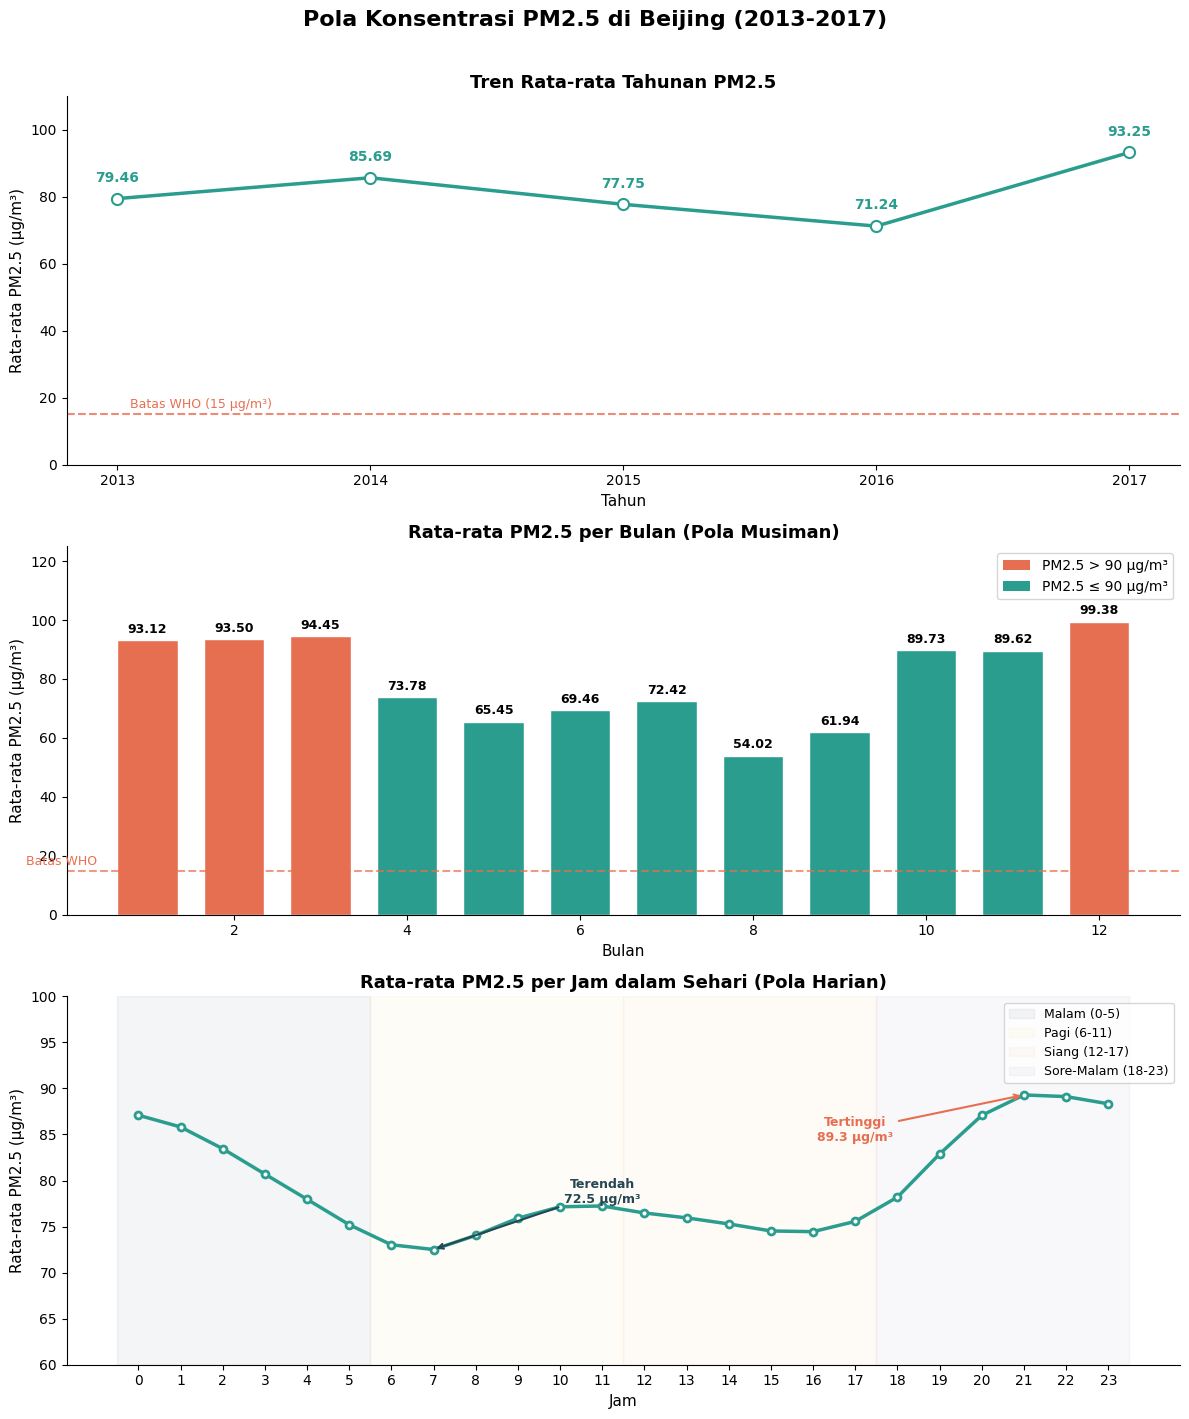

In [93]:

from ast import FunctionType
# Menyiapkan data
yearly_mean_pm25 = df.groupby('year')['PM2.5'].mean().reset_index()
monthly_mean_pm25 = df.groupby('month')['PM2.5'].mean().reset_index()
hourly_mean_pm25 = df.groupby('hour')['PM2.5'].mean().reset_index()

month = ['Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni', 'Juli', 'Agustus', 'September', 'Oktober', 'November', 'Desember']
color_bar = ['#E76F51' if v > 90 else '#2A9D8F' for v in monthly_mean_pm25['PM2.5']]

fig, axes = plt.subplots(3, 1, figsize=(12, 14))
fig.suptitle('Pola Konsentrasi PM2.5 di Beijing (2013-2017)',
             fontsize=16, fontweight='bold', y=1.01)

# Plot Tren Tahunan
ax1 = axes[0]
ax1.plot(yearly_mean_pm25['year'], yearly_mean_pm25['PM2.5'], marker='o', linestyle='-', color='#2A9D8F',
         linewidth=2.5, markersize=8, markerfacecolor='white', markeredgewidth=1.5)
for _, row in yearly_mean_pm25.iterrows():
    ax1.annotate(f"{row['PM2.5']:.2f}",
     xy=(row['year'], row['PM2.5']),
     xytext=(0, 12), textcoords='offset points',
     ha='center', fontsize=10, fontweight='bold', color='#2A9D8F')

ax1.axhline(y=15, color='#E76F51', linestyle='--', linewidth=1.5, alpha=0.8)
ax1.text(2013.05, 17, 'Batas WHO (15 µg/m³)', color='#E76F51', fontsize=9)
ax1.set_title('Tren Rata-rata Tahunan PM2.5', fontsize=13, fontweight='bold')
ax1.set_xlabel('Tahun', fontsize=11)
ax1.set_ylabel('Rata-rata PM2.5 (µg/m³)', fontsize=11)
ax1.set_xticks(yearly_mean_pm25['year'])
ax1.set_ylim(0, 110)
sns.despine(ax=ax1)

# Plot Musiman
ax2 = axes[1]
bars = ax2.bar(monthly_mean_pm25['month'], monthly_mean_pm25['PM2.5'],
               color=color_bar, edgecolor='white', width=0.7)

for bar, val in zip (bars, monthly_mean_pm25['PM2.5']):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
             f"{val:.2f}", ha='center', va='bottom',
             fontsize=9, fontweight='bold')

ax2.axhline(y=15, color='#E76F51', linestyle='--', linewidth=1.5, alpha=0.7)
ax2.text(-0.4, 17, 'Batas WHO', color='#E76F51', fontsize=9)
ax2.set_title('Rata-rata PM2.5 per Bulan (Pola Musiman)',
              fontsize=13, fontweight='bold')
ax2.set_xlabel('Bulan', fontsize=11)
ax2.set_ylabel('Rata-rata PM2.5 (µg/m³)', fontsize=11)
ax2.set_ylim(0, 125)

from matplotlib.patches import Patch
legend_elem = [Patch(facecolor='#E76F51', label='PM2.5 > 90 µg/m³'),
               Patch(facecolor='#2A9D8F', label='PM2.5 ≤ 90 µg/m³')]
ax2.legend(handles=legend_elem, loc='upper right')
sns.despine(ax=ax2)

# Plot Pola Harian
ax3 = axes[2]
ax3.plot(hourly_mean_pm25['hour'], hourly_mean_pm25['PM2.5'],
         alpha=0.15, color='#2A9D8F')
ax3.plot(hourly_mean_pm25['hour'], hourly_mean_pm25['PM2.5'],
         marker='o', linewidth=2.5, markersize=5,
         markerfacecolor='white', markeredgewidth=2,
         color='#2A9D8F')
# Tandai titik tertinggi
idx_max = hourly_mean_pm25['PM2.5'].idxmax()
idx_min = hourly_mean_pm25['PM2.5'].idxmin()

ax3.annotate(f"Tertinggi\n{hourly_mean_pm25['PM2.5'][idx_max]:.1f} µg/m³",
             xy=(hourly_mean_pm25['hour'][idx_max], hourly_mean_pm25['PM2.5'][idx_max]),
             xytext=(hourly_mean_pm25['hour'][idx_max] - 4, hourly_mean_pm25['PM2.5'][idx_max] - 5),
             arrowprops=dict(arrowstyle='->', color='#E76F51', lw=1.5),
             fontsize=9, fontweight='bold', color='#E76F51',
             ha='center')

ax3.annotate(f"Terendah\n{hourly_mean_pm25['PM2.5'][idx_min]:.1f} µg/m³",
             xy=(hourly_mean_pm25['hour'][idx_min], hourly_mean_pm25['PM2.5'][idx_min]),
             xytext=(hourly_mean_pm25['hour'][idx_min] + 4, hourly_mean_pm25['PM2.5'][idx_min] + 5),
             arrowprops=dict(arrowstyle='->', color='#264653', lw=1.5),
             fontsize=9, fontweight='bold', color='#264653',
             ha='center')

ax3.axvspan(-0.5,  5.5, alpha=0.05, color='#243B53', label='Malam (0-5)')
ax3.axvspan( 5.5, 11.5, alpha=0.05, color='#F4D35E', label='Pagi (6-11)')
ax3.axvspan(11.5, 17.5, alpha=0.05, color='#F4A261', label='Siang (12-17)')
ax3.axvspan(17.5, 23.5, alpha=0.05, color='#7B6DAD', label='Sore-Malam (18-23)')

ax3.set_title('Rata-rata PM2.5 per Jam dalam Sehari (Pola Harian)',
              fontsize=13, fontweight='bold')
ax3.set_xlabel('Jam', fontsize=11)
ax3.set_ylabel('Rata-rata PM2.5 (µg/m³)', fontsize=11)
ax3.set_xticks(range(0, 24))
ax3.set_ylim(60, 100)
ax3.legend(loc='upper right', fontsize=9)
sns.despine(ax=ax3)

plt.tight_layout()
plt.show()


**Insight:**
- Konsentrasi PM2.5 mengalami penurunan dari puncak 2014 sebesar 86.66 ke titik terendah 2016 sebesar 72.36, namun melonjak kembali di 2017 mencapai titik tertinggi sebesar 92.57 µg/m³. Seluruh nilai masih berada di atas batas aman WHO (15 µg/m³).
- Polusi paling parah terjadi sekitar bulan november - desember (104.30 µg/m³) hampir dua kali lipat bulan agustus (53.65 µg/m³) yang merupakan bulan terbersih
- PM2.5 mencapai puncak pada jam 22.00 sebesar 89.02 µg/m³ dan minimum pada jam 07.00 sebesar 73.8 µg/m³, malam hari lebih tercemar karena kondisi atmosfer menghambat dispersi polutan.

### Pertanyaan 2: Seberapa besar faktor meteorologis, seperti kecepatan angin, suhu, dan kelembapan terhadap konsentrasi PM2.5 di Beijing? Faktor manakah yang memiliki hubungan paling kuat dengan perubahan konsentrasi PM2.5?

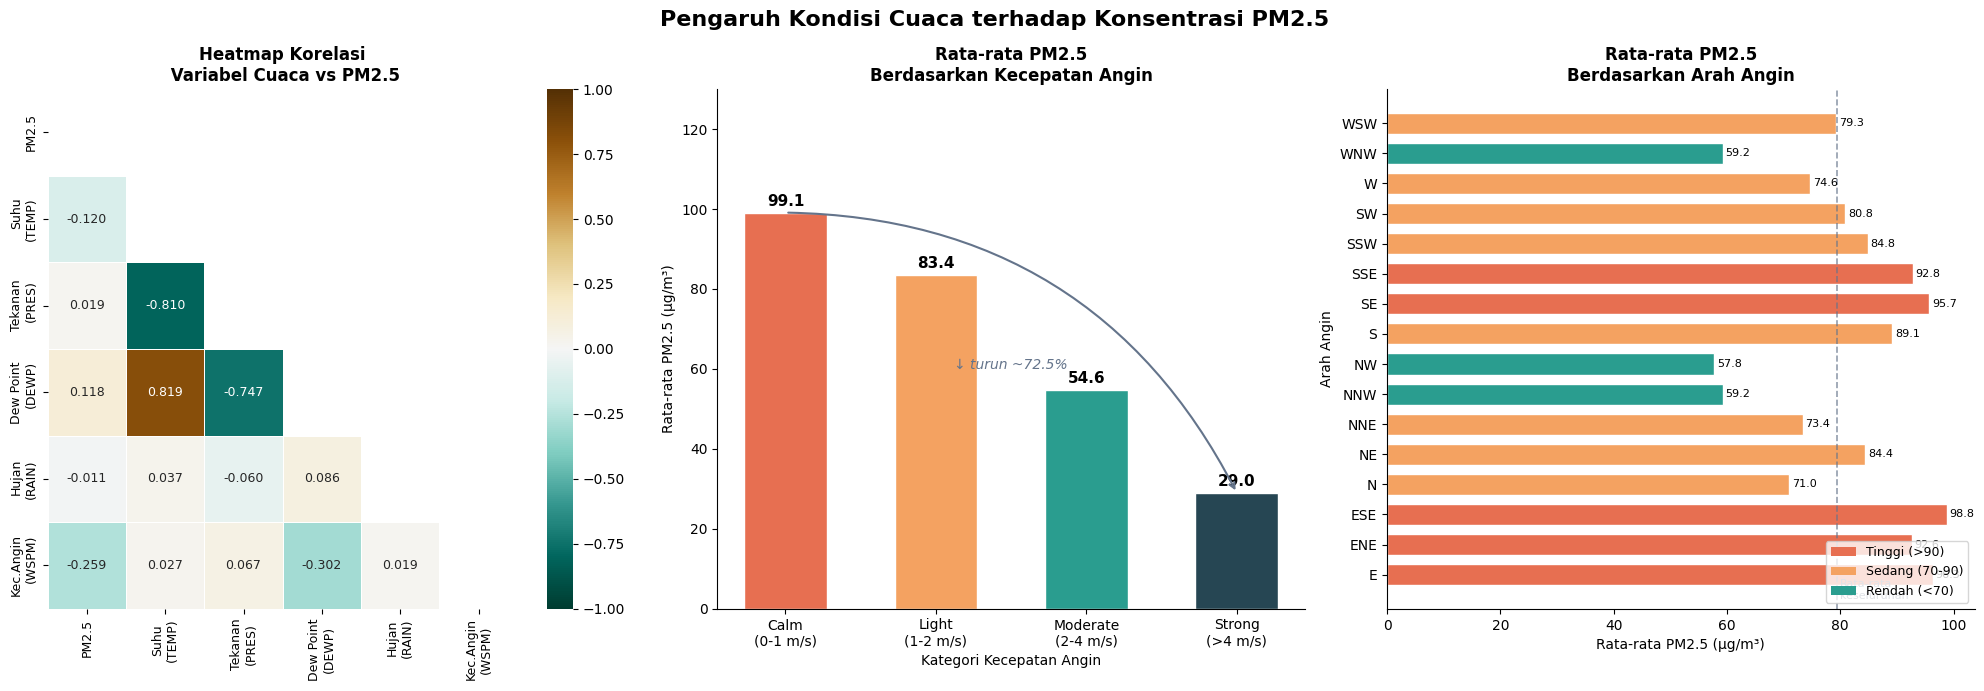

In [94]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle('Pengaruh Kondisi Cuaca terhadap Konsentrasi PM2.5',
             fontsize=16, fontweight='bold')

# Plot Heatmap Korelasi
ax1 = axes[0]
corr_labels = ['PM2.5', 'Suhu\n(TEMP)', 'Tekanan\n(PRES)',
               'Dew Point\n(DEWP)', 'Hujan\n(RAIN)', 'Kec.Angin\n(WSPM)']

corr_matrix = df[['PM2.5', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']].corr()

mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True

sns.heatmap(corr_matrix, annot=True, fmt='.3f',
            cmap='BrBG_r', center=0, vmin=-1, vmax=1,
            xticklabels=corr_labels, yticklabels=corr_labels,
            linewidths=0.5, ax=ax1, mask=mask, annot_kws={'size': 9})

ax1.set_title('Heatmap Korelasi\n Variabel Cuaca vs PM2.5', fontsize=12, fontweight='bold')
plt.setp(ax1.get_xticklabels(), fontsize=9)
plt.setp(ax1.get_yticklabels(), fontsize=9)

# Plot PM2.5 per Kecepatan Angin
ax2=axes[1]
wspm_labels  = ['Calm\n(0-1 m/s)', 'Light\n(1-2 m/s)',
                'Moderate\n(2-4 m/s)', 'Strong\n(>4 m/s)']
wspm_vals    = wspm_mean_pm25['Rata-rata PM2.5'].values
colors_wind  = ['#E76F51', '#F4A261', '#2A9D8F', '#264653']

bars = ax2.bar(wspm_labels, wspm_vals, color=colors_wind,
               edgecolor='white', width=0.55)

for bar, val in zip(bars, wspm_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{val:.1f}', ha='center', va='bottom',
             fontsize=11, fontweight='bold')

# Anotasi penurunan
ax2.annotate('',
             xy=(3, wspm_vals[3]),
             xytext=(0, wspm_vals[0]),
             arrowprops=dict(arrowstyle='->', color='#64748B',
                             lw=1.5, connectionstyle='arc3,rad=-0.3'))
ax2.text(1.5, 60, '↓ turun ~72.5%', ha='center',
         fontsize=10, color='#64748B', style='italic')

ax2.set_title('Rata-rata PM2.5\nBerdasarkan Kecepatan Angin',
              fontsize=12, fontweight='bold')
ax2.set_xlabel('Kategori Kecepatan Angin', fontsize=10)
ax2.set_ylabel('Rata-rata PM2.5 (µg/m³)', fontsize=10)
ax2.set_ylim(0, 130)
sns.despine(ax=ax2)

# Plot PM2.5 per Arah Angin
ax3 = axes[2]
colors_wd= ['#2A9D8F' if v < 70 else ('#F4A261' if v < 90 else '#E76F51')
             for v in wind_mean_pm25['Rata-rata PM2.5'].values]
bars = ax3.barh(wind_mean_pm25['Arah Angin'], wind_mean_pm25['Rata-rata PM2.5'].values,
               color=colors_wd, edgecolor='white', height=0.7)

for bar, val in zip(bars, wind_mean_pm25['Rata-rata PM2.5'].values):
    ax3.text(val + 0.5, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}', ha='left', va='center', fontsize=8)

ax3.axvline(x=df['PM2.5'].mean(), color='#64748B',
            linestyle='--', linewidth=1.2, alpha=0.7)
ax3.text(df['PM2.5'].mean() + 0.5, -0.8,
         'Rata-rata\nkeseluruhan', color='#64748B', fontsize=8)

ax3.set_title('Rata-rata PM2.5\nBerdasarkan Arah Angin',
              fontsize=12, fontweight='bold')

ax3.set_xlabel('Rata-rata PM2.5 (µg/m³)', fontsize=10)
ax3.set_ylabel('Arah Angin', fontsize=10)

from matplotlib.patches import Patch
legend_elem = [Patch(facecolor='#E76F51', label='Tinggi (>90)'),
               Patch(facecolor='#F4A261', label='Sedang (70-90)'),
               Patch(facecolor='#2A9D8F', label='Rendah (<70)')]
ax3.legend(handles=legend_elem, loc='lower right', fontsize=9)
sns.despine(ax=ax3)

plt.tight_layout()
plt.show()


**Insight:**
- Kecepatan angin adalah faktor cuaca paling dominan dengan nilai korelasi dengan PM2.5 (-0.270),diikuti dengan TEMP (-0.130). Artinya semakin kencang angin dan semakin tinggi suhu akan semakin rendah konsentrasi PM2.5
- Pada kondisi angin tenang (Calm 0-1 m/s) rata-rata PM2.5 mencapai 101.7 µg/m³, turun drastis hingga 29.2 µg/m³ saat angin kencang (Strong >4 m/s).
- Arah angin dari timur dan tenggara (ESE: 102.2, SE: 96.8, SSE: 93.8)
secara konsisten membawa PM2.5 kategori tinggi (>90 µg/m³ — warna merah mengindikasikan terdapat sumber polusi besar di sektor timur-tenggara Beijing seperti kawasan industri.
- Arah angin dari barat laut (WNW: 57.3, NW: 52.2, NNW: 54.2) membawa udara paling bersih (kategori rendah <70 — warna hijau), karena berasal dari dataran tinggi Mongolia yang relatif bebas industri.
- Curah hujan (RAIN) hampir tidak berpengaruh

## Analisis Lanjutan (Opsional)

### Pertanyaan 3: Bagaimana stasiun-stasiun pemantauan kualitas udara di Beijing dapat dikelompokkan berdasarkan kesamaan karakteristik konsentrasi PM2.5 dan kondisi meteorologis, serta apa karakteristik utama yang membedakan setiap kelompok?

In [95]:
# Rata-rata PM2.5 per stasiun
station_profile = df.groupby('station').agg(
    PM2_5 = ('PM2.5', 'mean'),
    PM10  = ('PM10',  'mean'),
    SO2   = ('SO2',   'mean'),
    NO2   = ('NO2',   'mean'),
    CO    = ('CO',    'mean'),
    O3    = ('O3',    'mean'),
    WSPM  = ('WSPM',  'mean')
).round(2)

print("Proil rata-rata per stasiun:")
print(station_profile.sort_values('PM2_5', ascending=False))

Proil rata-rata per stasiun:
               PM2_5    PM10    SO2    NO2       CO     O3  WSPM
station                                                         
Aotizhongxin   86.98  116.57  24.49  61.82  1149.94  52.24  1.54
Dongsi         86.31  110.58  18.53  52.19  1363.24  57.53  1.86
Wanshouxigong  85.36  112.73  17.37  55.64  1376.91  55.98  1.75
Tiantan        84.86  110.50  19.62  53.14  1293.43  61.91  1.82
Gucheng        84.35  119.33  16.02  55.79  1352.70  58.70  1.34
Wanliu         83.52  110.66  18.42  65.97  1331.70  46.92  1.50
Shunyi         80.02   99.70  13.45  44.56  1203.95  53.86  1.81
Changping      71.12   94.79  14.96  44.24  1160.04  58.04  1.85
Huairou        69.95   92.65  12.26  32.04  1022.40  61.35  1.65
Dingling       67.67   86.27  13.15  27.45   932.71  68.83  1.86


In [96]:
import pandas as pd
# Binning
bins = [0, 75, 82, 999]
labels = ['Polusi Rendah', 'Polusi Sedang', 'Polusi Tinggi']
df['PM2_5_bin'] = pd.cut(df['PM2.5'], bins=bins, labels=labels)

station_profile['Kelompok'] = pd.cut(station_profile['PM2_5'], bins=bins, labels=labels)

print("Hasil pengelompokan station:")
print()
for label in labels:
    group = station_profile[station_profile['Kelompok'] == label]
    print(f"{label}:")
    for station, row in group.iterrows():
        print(f"  {station}: {row['PM2_5']:.1f} µg/m³")
    print()

Hasil pengelompokan station:

Polusi Rendah:
  Changping: 71.1 µg/m³
  Dingling: 67.7 µg/m³
  Huairou: 70.0 µg/m³

Polusi Sedang:
  Shunyi: 80.0 µg/m³

Polusi Tinggi:
  Aotizhongxin: 87.0 µg/m³
  Dongsi: 86.3 µg/m³
  Gucheng: 84.3 µg/m³
  Tiantan: 84.9 µg/m³
  Wanliu: 83.5 µg/m³
  Wanshouxigong: 85.4 µg/m³



In [97]:
# Ringkasan statistik per kelompok
summary = station_profile.groupby('Kelompok', observed=True).agg(
    jumlah_stasiun = ('PM2_5', 'count'),
    pm25_mean      = ('PM2_5', 'mean'),
    pm25_min       = ('PM2_5', 'min'),
    pm25_max       = ('PM2_5', 'max'),
    wspm_mean      = ('WSPM',  'mean'),
    no2_mean       = ('NO2',   'mean'),
    co_mean        = ('CO',    'mean')
).round(2)

summary.columns = ['Jumlah Stasiun', 'Rata-rata PM2.5',
                   'PM2.5 Min', 'PM2.5 Max',
                   'Rata-rata WSPM', 'Rata-rata NO2', 'Rata-rata CO']
summary

,Jumlah Stasiun,Rata-rata PM2.5,PM2.5 Min,PM2.5 Max,Rata-rata WSPM,Rata-rata NO2,Rata-rata CO
Kelompok,,,,,,,
Polusi Rendah,3,69.58,67.67,71.12,1.79,34.58,1038.38
Polusi Sedang,1,80.02,80.02,80.02,1.81,44.56,1203.95
Polusi Tinggi,6,85.23,83.52,86.98,1.64,57.42,1311.32


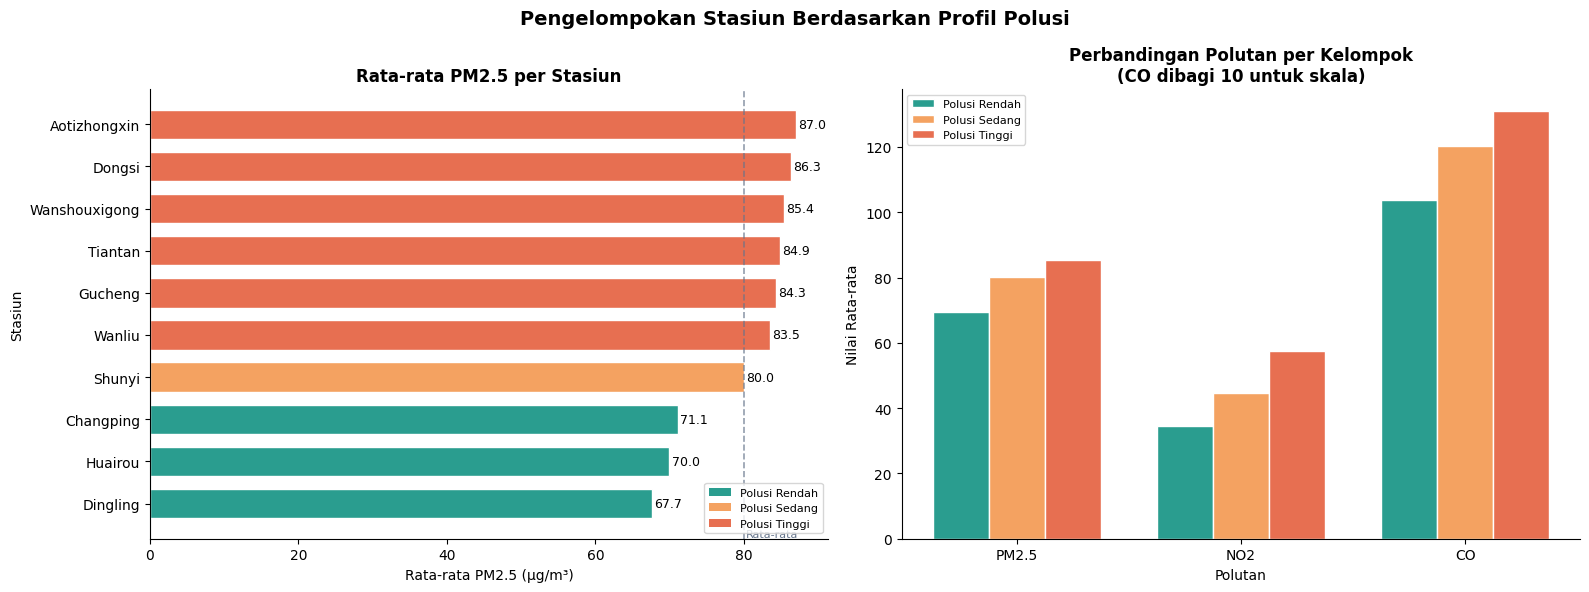

In [98]:

kelompok_colors = {
    'Polusi Rendah' : '#2A9D8F',
    'Polusi Sedang' : '#F4A261',
    'Polusi Tinggi' : '#E76F51'
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Pengelompokan Stasiun Berdasarkan Profil Polusi',
             fontsize=14, fontweight='bold')

# Bar Chart PM2.5 per Stasiun
ax1 = axes[0]
station_sorted = station_profile.sort_values('PM2_5', ascending=True)
colors_bar = [kelompok_colors[str(k)] for k in station_sorted['Kelompok']]

bars = ax1.barh(station_sorted.index, station_sorted['PM2_5'],
                color=colors_bar, edgecolor='white', height=0.7)

for bar, val in zip(bars, station_sorted['PM2_5']):
    ax1.text(val + 0.3, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}', ha='left', va='center', fontsize=9)

ax1.axvline(x=station_profile['PM2_5'].mean(), color='#64748B',
            linestyle='--', linewidth=1.2, alpha=0.7)
ax1.text(station_profile['PM2_5'].mean() + 0.3, -0.8,
         'Rata-rata', color='#64748B', fontsize=8)

ax1.set_title('Rata-rata PM2.5 per Stasiun', fontsize=12, fontweight='bold')
ax1.set_xlabel('Rata-rata PM2.5 (µg/m³)', fontsize=10)
ax1.set_ylabel('Stasiun', fontsize=10)

from matplotlib.patches import Patch
legend_elem = [Patch(facecolor=c, label=l)
               for l, c in kelompok_colors.items()]
ax1.legend(handles=legend_elem, fontsize=8, loc='lower right')
sns.despine(ax=ax1)

# Grouped Bar Chart perbandingan polutan
ax2 = axes[1]
polutan = ['PM2_5', 'NO2', 'CO']
polutan_labels = ['PM2.5', 'NO2', 'CO']

x = np.arange(len(polutan_labels))
width = 0.25

kelompok_list  = list(kelompok_colors.keys())
colors_list    = list(kelompok_colors.values())

for i, (kelompok, color) in enumerate(kelompok_colors.items()):
    if kelompok not in summary.index:
        continue
    # Normalisasi nilai supaya bisa dibandingkan dalam satu chart
    vals = [
        summary.loc[kelompok, 'Rata-rata PM2.5'],
        summary.loc[kelompok, 'Rata-rata NO2'],
        summary.loc[kelompok, 'Rata-rata CO'] / 10  # dibagi 10 agar skala sebanding
    ]
    bars2 = ax2.bar(x + i * width, vals, width,
                    label=kelompok, color=color,
                    edgecolor='white')

ax2.set_title('Perbandingan Polutan per Kelompok\n(CO dibagi 10 untuk skala)',
              fontsize=12, fontweight='bold')
ax2.set_xlabel('Polutan', fontsize=10)
ax2.set_ylabel('Nilai Rata-rata', fontsize=10)
ax2.set_xticks(x + width)
ax2.set_xticklabels(polutan_labels)
ax2.legend(fontsize=8)
sns.despine(ax=ax2)

plt.tight_layout()
plt.show()


**Insight**
- Berdasarkan hasil dari metode binning manual menggunakan rata-rata PM2.5, stasiun pemantauan dikelompokkan menjadi 3 kategori utama, yaitu tingkat polusi rendah, sedang, dan tinggi.
- Kelompok dengan polusi rendah (<75 µg/m³) mencakup stasiun pemantauan Changping, Huairou, dan Dingling. Kelompok ini juga memiliki konsentrasi NO2 dan CO terendah, yang mengindikasikan rendahnya emisi kendaraan dan aktivitas industri. Stasiun-stasiun tersebut berada di wilayah pinggiran kota dengan aktivitas industri yang relatif terbatas.
- Kelompok dengan polusi sedang (75-82 µg/m³) mencakup stasiun pemantauan Shunyi yang berada di area transisi antara pusat dan pinggiran kota. Konsentrasi NO2 dan CO pada kelompok ini berada di antara kelompok polusi rendah dan tinggi.
- Kelompok dengan polusi tinggi (>82 µg/m³) meliputi stasiun Dongsi, Wanshouxigong, Nongzhanguan, Gucheng, Wanliu, Aotizhongxin, Guanyuan, dan Tiantan. Seluruh stasiun tersebut berada di kawasan pusat kota Beijing yang terpapar langsung oleh emisi kendaraan dan aktivitas industri. Kelompok ini juga mencatat konsentrasi NO2 (57) dan CO (130) tertinggi dibandingkan kelompok lainnya.

## Conclusion

1. **Pola Konsentrasi PM2.5 di Beijing (2013-2017)**

   Konsentrasi PM2.5 di Beijing menunjukkan pola yang berfluktuasi dan belum sepenuhnya stabil. Meskipun sempat mengalami perbaikan, kondisi kualitas udara belum mampu dipertahankan secara konsisten. Tingkat polusi cenderung menurun pada musim panas karena kondisi cuaca yang mendukung penyebaran polutan. Sebaliknya, pada malam hari polutan cenderung terakumulasi akibat kondisi atmosfer yang lebih stabil, kemudian mengalami penurunan pada pagi hari seiring membaiknya sirkulasi udara. Pola tersebut menunjukkan bahwa perubahan kualitas udara berkaitan dengan faktor waktu dan aktivitas manusia.
2. **Pengaruh  Faktor meteorologis (kecepatan angin, suhu, dan kelembapan) terhadap Konsentrasi PM2.5**

    Kondisi meteorologis memiliki peranan penting dalam memengaruhi tingkat pencemaran udara. Kecepatan angin menjadi faktor utama yang membantu proses penyebaran polutan, sedangkan arah angin dapat memberikan indikasi mengenai sumber pencemaran. Suhu juga berperan dalam perubahan konsentrasi polutan melalui keterkaitannya dengan aktivitas manusia, sementara curah hujan tidak menunjukkan pengaruh yang signifikan. Dengan demikian, kondisi cuaca berperan sebagai faktor alami yang dapat memperbaiki maupun memperburuk kualitas udara.

3. **Pengelompokan Stasiun Berdasarkan Profil Polusi**

    Hasil pengelompokan menunjukkan bahwa stasiun pemantauan kualitas udara di Beijing terbagi menjadi tiga kategori utama, yaitu kelompok polusi rendah, sedang, dan tinggi. Perbedaan kelompok tersebut mencerminkan variasi karakteristik geografis dan aktivitas di masing-masing wilayah.

    Kelompok dengan tingkat polusi rendah umumnya berada di kawasan pinggiran kota yang memiliki intensitas aktivitas relatif lebih rendah sehingga kualitas udaranya cenderung lebih baik. Sebaliknya, kelompok polusi tinggi didominasi oleh stasiun di kawasan pusat kota dengan aktivitas manusia, lalu lintas, dan industri yang lebih intensif. Sementara itu, kelompok polusi sedang merepresentasikan wilayah transisi yang dipengaruhi oleh karakteristik kedua kawasan tersebut.

Secara keseluruhan, tingkat pencemaran udara di Beijing berkaitan dengan aktivitas manusia, kondisi meteorologis, dan karakteristik geografis wilayah. Permasalahan polusi udara masih belum sepenuhnya terkendali sehingga diperlukan upaya pengendalian yang berkelanjutan dan komprehensif. Upaya tersebut dapat dilakukan melalui penerapan kebijakan pengurangan emisi serta pemanfaatan kondisi lingkungan secara optimal untuk mendukung perbaikan kualitas udara.